In [3]:
import numpy as np
import cv2 as cv
from matplotlib import pyplot as plt

# Задание 1

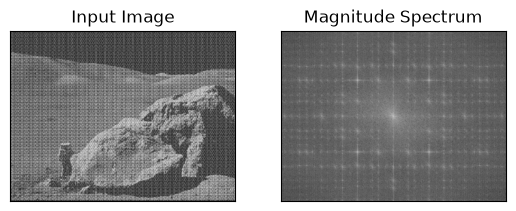

In [4]:
img = cv.imread('periodic_noise.jpg', cv.IMREAD_GRAYSCALE)

dft = cv.dft(np.float32(img),flags = cv.DFT_COMPLEX_OUTPUT)
dft_shift = np.fft.fftshift(dft)

magnitude_spectrum = 20*np.log(cv.magnitude(dft_shift[:,:,0],dft_shift[:,:,1]))

plt.subplot(121),plt.imshow(img, cmap = 'gray')
plt.title('Input Image'), plt.xticks([]), plt.yticks([])
plt.subplot(122),plt.imshow(magnitude_spectrum, cmap = 'gray')
plt.title('Magnitude Spectrum'), plt.xticks([]), plt.yticks([])
plt.show()

In [ ]:
#Filter creating
D0 = 10
mask = np.zeros((img.shape[0],img.shape[1],2),np.float32)
centerX, centerY = (int(img.shape[0] / 2),int(img.shape[1] / 2))
for i in range(img.shape[0]):
    for j in range(img.shape[1]):
        D2 = (i - centerX)**2 + (j - centerY)**2
        mask[i,j,:] = 1 - np.exp(-D2 / (2 * D0**2))

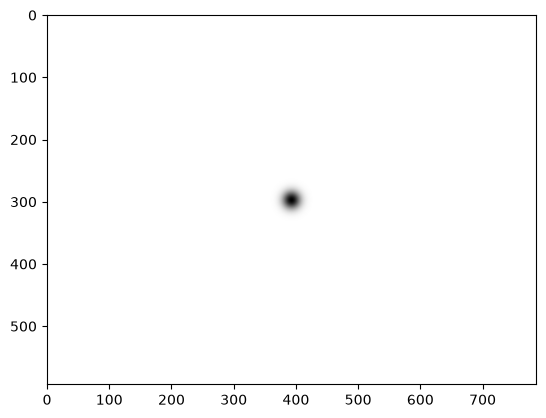

In [6]:
plt.imshow(mask[:,:,0], cmap = 'gray')

In [ ]:
fshift = dft_shift*mask

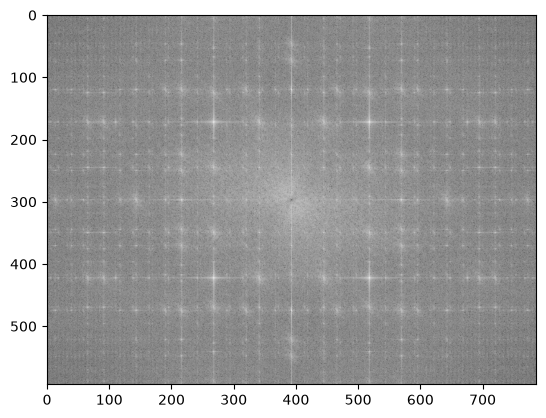

In [ ]:
filtering_magn_res = 20*np.log(cv.magnitude(fshift[:,:,0],fshift[:,:,1]) + 1)
plt.imshow(filtering_magn_res, cmap='gray')

In [9]:
f_ishift = np.fft.ifftshift(fshift)
img_back = cv.idft(f_ishift)
img_back = cv.magnitude(img_back[:,:,0],img_back[:,:,1])

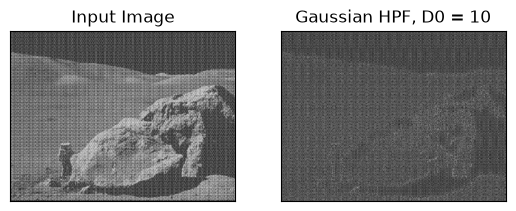

In [10]:
plt.subplot(121),plt.imshow(img, cmap = 'gray')
plt.title('Input Image'), plt.xticks([]), plt.yticks([])
plt.subplot(122),plt.imshow(img_back, cmap = 'gray')
plt.title('Gaussian HPF, D0 = 10'), plt.xticks([]), plt.yticks([])
plt.show()

# Задание 2

In [ ]:
#Свертка через преобразование Фурье
kernel = np.ones((5,5),np.float32)/25

kernel_pad = np.zeros(img.shape, np.float32)
kh, kw = kernel.shape
kernel_pad[:kh, :kw] = kernel
kernel_pad = np.roll(kernel_pad, (-(kh // 2), -(kw // 2)), axis=(0, 1))

In [12]:
dft_img = cv.dft(np.float32(img), flags = cv.DFT_COMPLEX_OUTPUT)
dft_kernel = cv.dft(kernel_pad, flags = cv.DFT_COMPLEX_OUTPUT)

In [ ]:
dft_res = cv.mulSpectrums(dft_img, dft_kernel, 0)
img_conv = cv.idft(dft_res, flags = cv.DFT_SCALE | cv.DFT_REAL_OUTPUT)

In [ ]:
img_2d = cv.filter2D(np.float32(img), -1, kernel)
diff = np.abs(img_conv - img_2d)[5:-5, 5:-5]
print('максимальная разница:', diff.max())

максимальная разница: 0.00012207031


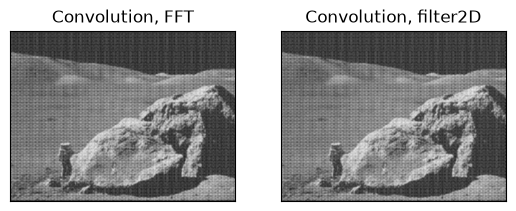

In [15]:
plt.subplot(121),plt.imshow(img_conv, cmap = 'gray')
plt.title('Convolution, FFT'), plt.xticks([]), plt.yticks([])
plt.subplot(122),plt.imshow(img_2d, cmap = 'gray')
plt.title('Convolution, filter2D'), plt.xticks([]), plt.yticks([])
plt.show()

# Задание 3

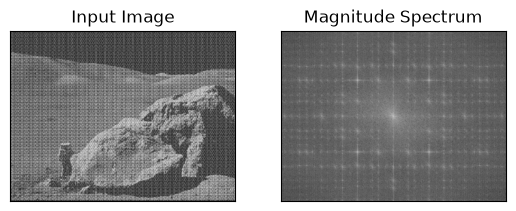

In [16]:
img = cv.imread('periodic_noise.jpg', cv.IMREAD_GRAYSCALE)

dft = cv.dft(np.float32(img),flags = cv.DFT_COMPLEX_OUTPUT)
dft_shift = np.fft.fftshift(dft)

magnitude_spectrum = 20*np.log(cv.magnitude(dft_shift[:,:,0],dft_shift[:,:,1]))

plt.subplot(121),plt.imshow(img, cmap = 'gray')
plt.title('Input Image'), plt.xticks([]), plt.yticks([])
plt.subplot(122),plt.imshow(magnitude_spectrum, cmap = 'gray')
plt.title('Magnitude Spectrum'), plt.xticks([]), plt.yticks([])
plt.show()

In [ ]:
#Filter creating
T = 250  
R = 25   
d = 2     

mask = np.ones((img.shape[0],img.shape[1],2),np.uint8)
centerX, centerY = (int(img.shape[0] / 2),int(img.shape[1] / 2))

peaks = np.argwhere(magnitude_spectrum > T)
count = 0
for x, y in peaks:
    if (x - centerX)**2 + (y - centerY)**2 > R**2:
        mask[x-d:x+d+1, y-d:y+d+1, :] = 0
        count += 1
print('найдено пиков шума:', count)

найдено пиков шума: 473


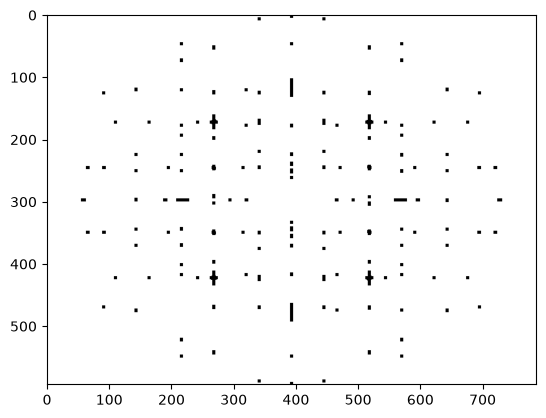

In [18]:
plt.imshow(mask[:,:,0], cmap = 'gray')

In [ ]:
fshift = dft_shift*mask

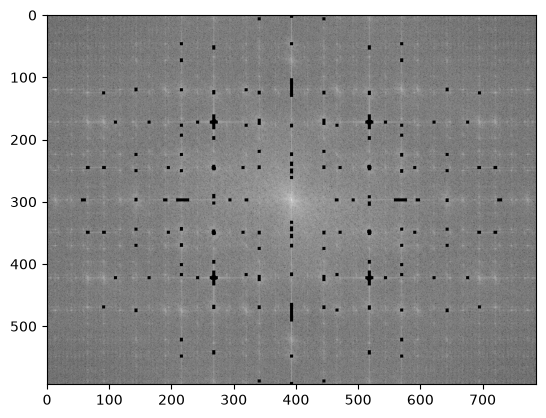

In [ ]:
filtering_magn_res = 20*np.log(cv.magnitude(fshift[:,:,0],fshift[:,:,1]) + 1)
plt.imshow(filtering_magn_res, cmap='gray')

In [21]:
f_ishift = np.fft.ifftshift(fshift)
img_back = cv.idft(f_ishift)
img_back = cv.magnitude(img_back[:,:,0],img_back[:,:,1])

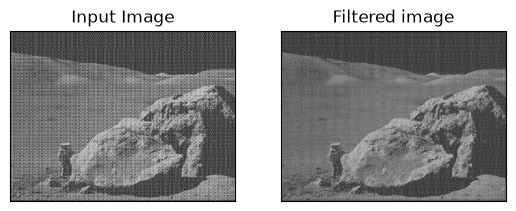

In [22]:
plt.subplot(121),plt.imshow(img, cmap = 'gray')
plt.title('Input Image'), plt.xticks([]), plt.yticks([])
plt.subplot(122),plt.imshow(img_back, cmap = 'gray')
plt.title('Filtered image'), plt.xticks([]), plt.yticks([])
plt.show()